In [23]:
import numpy as np
from abc import ABC, abstractmethod
from typing import Tuple, List, Dict, Optional
from scipy.optimize import fsolve
import matplotlib.pyplot as plt

In [24]:
# Utility

def midpoint ( f, tspan, y0, n ):

#*****************************************************************************80
#
## midpoint() uses the implicit midpoint method to solve an ODE.
#
#  Licensing:
#
#    This code is distributed under the MIT license.
#
#  Modified:
#
#    13 November 2024
#
#  Author:
#
#    John Burkardt
#
#  Reference:
#
#    Catalin Trenchea, John Burkardt,
#    Refactorization of the midpoint rule,
#    Applied Mathematics Letters,
#    Volume 107, September 2020.
#
#  Input:
#
#    function f: evaluates the right hand side of the ODE.
#
#    real tspan[2]: the starting and ending times.
#
#    real y0[m]: the initial conditions.
#
#    integer n: the number of steps.
#
#  Output:
#
#    real t[n+1], y[n+1,m]: the solution estimates.
#


  if ( np.ndim ( y0 ) == 0 ):
    m = 1
  else:
    m = len ( y0 )

  t = np.zeros ( n + 1 )
  y = np.zeros ( [ n + 1, m ] )

  dt = ( tspan[1] - tspan[0] ) / float ( n )

  t[0] = tspan[0];
  y[0,:] = y0

  for i in range ( 0, n ):

    to = t[i]
    yo = y[i,:]

    th = to + 0.5 * dt
    yh = yo + 0.5 * dt * f ( to, yo ) # To provide a high-quality initial guess for the iterative solver fsolve: explicit Euler step to the midpoint.
    yh = fsolve ( midpoint_residual, yh, args = ( f, to, yo, th ), xtol=1e-12)

    tp = to + dt
    yp = 2.0 * yh - yo

    t[i+1]   = tp
    y[i+1,:] = yp

  return t, y

def midpoint_residual ( yh, f, to, yo, th ):

#*****************************************************************************80
#
## midpoint_residual() evaluates the midpoint residual.
#
#  Discussion:
#
#    We are seeking a value YH defined by the implicit equation:
#
#      YH = YO + ( TH - TO ) * F ( TH, YH )
#
#  Licensing:
#
#    This code is distributed under the MIT license.
#
#  Modified:
#
#    21 October 2020
#
#  Author:
#
#    John Burkardt
#
#  Input:
#
#    real yh: the estimated solution value at the midpoint time.
#
#    function f: evaluates the right hand side of the ODE.
#
#    real to, yo: the old time and solution value.
#
#    real th: the midpoint time.
#
#  Output:
#
#    real value: the midpoint residual.
#
  value = yh - yo - ( th - to ) * f ( th, yh ) # (th - to) = (to + 0.5 * dt) - to = 0.5 * dt

  return value

# DynamicalSystem Abstract Class

Abstract base class for Hamiltonian dynamical systems where state = [q, p] (configuration + momentum).

## Constructor
- `__init__(name, state_dim, **params)` - Initialize with system name, state dimension, and parameters

## Abstract Methods (Must Implement)
- `dynamics(t, state)` → Returns time derivative [dq/dt, dp/dt] using Hamilton's equations
- `hamiltonian(state)` → Returns total energy H(q, p)
- `generate_initial_conditions(n_trajectories, seed)` → Returns random initial states

## Concrete Methods
- `simulate_trajectory(initial_state, tspan, steps)` → Simulates system using midpoint method, returns (time, trajectory)
- `trajectory_energy(trajectory)` → Computes energy along trajectory
- `validate_state(state)` → Checks state has correct dimensions


In [25]:
class DynamicalSystem(ABC):
    """Abstract base class for dynamical systems in Hamiltonian form"""

    def __init__(self, name: str, state_dim: int, **params):
        self.name = name
        self.state_dim = state_dim
        self.params = params

    @abstractmethod
    def dynamics(self, t: float, state: np.ndarray) -> np.ndarray:
        """
        Compute the time derivative of the state using Hamilton's equations.
        State is [q1, ..., qn, p1, ..., pn] where q are configurations and p are momenta.

        Args:
            t: Current time
            state: Current state vector of dimension state_dim

        Returns:
            Time derivative of state vector [dq/dt, dp/dt]
        """
        pass

    @abstractmethod
    def hamiltonian(self, state: np.ndarray) -> float:
        """
        Compute the Hamiltonian (total energy) of the system.

        Args:
            state: Current state vector [q, p]

        Returns:
            Hamiltonian value H(q, p)
        """
        pass


    @abstractmethod
    def generate_initial_conditions(self, n_trajectories: int, seed: Optional[int] = None) -> np.ndarray:
        """
        Generate random initial conditions in phase space.

        Args:
            n_trajectories: Number of initial conditions to generate

        Returns:
            Array of shape (n_trajectories, state_dim) with [q, p] format
        """
        pass

    def simulate_trajectory(self, initial_state: np.ndarray, tspan: tuple, steps: int) -> tuple[np.ndarray, np.ndarray]:
        """
        Simulate a single trajectory of the system using the midpoint method.

        Args:
            initial_state (np.ndarray): Initial state vector of shape (state_dim,).
            tspan (tuple): Time span for simulation (t0, tf).
            steps (int): Number of integration steps.

        Returns:
            tuple:
                - t (np.ndarray): Array of time points of shape (steps+1,).
                - y (np.ndarray): Array of states at each time point of shape (steps+1, state_dim).
        """
        t, trajectory = midpoint(self.dynamics, tspan, initial_state, steps)
        return t, trajectory

    def trajectory_energy(self, trajectory: np.ndarray) -> np.ndarray:
        """
        Compute the Hamiltonian (energy) along a given trajectory.

        Args:
            trajectory (np.ndarray): Array of states along the trajectory, shape (n_steps, state_dim).

        Returns:
            np.ndarray: Array of energy values at each step, shape (n_steps,).
        """
        return np.array([self.hamiltonian(s) for s in trajectory])
        #return self.hamiltonian(trajectory) # This implementation is vectorized for efficiency. For very long trajectories, this Python-level loop can be a performance bottleneck. A more efficient, "NumPy-native" approach e.g. vectorization pushes the loop down into NumPy's optimized C code.

    def validate_state(self, state: np.ndarray) -> np.ndarray:
        """
        Validate the input state vector and ensure it has the correct dimensionality.

        Args:
            state (np.ndarray): Input state vector of shape (..., state_dim).

        Returns:
            np.ndarray: Validated state vector, unchanged if valid.

        Raises:
            ValueError: If the last dimension of `state` does not match `state_dim`.
        """
        if state.shape[-1] != self.state_dim:
            raise ValueError(f"State dimension mismatch: expected {self.state_dim}, got {state.shape[-1]}")
        return state


# SimplePendulum Class

Concrete implementation of a simple pendulum using Hamiltonian mechanics.

## Physics
Hamiltonian: **H = p²/(2mL²) + mgL(1-cos(q))**
- q: angle from vertical
- p: angular momentum
- Energy = kinetic + gravitational potential

## Constructor
```python
SimplePendulum(g=9.81, L=1.0, m=1.0)
```
- `g`: gravitational acceleration (m/s²)
- `L`: pendulum length (m)
- `m`: bob mass (kg)

## Implemented Methods
- `dynamics(t, state)` → Returns [dq/dt, dp/dt] = [p/(mL²), -mgL·sin(q)]
- `hamiltonian(state)` → Returns total energy (kinetic + potential)
- `generate_initial_conditions(n, seed)` → Random angles in [-π/3, π/3] and momenta in [-2mL², 2mL²]
- `get_plot_config()` → Returns dict with labels and phase space plotting ranges

## Usage
```python
pendulum = SimplePendulum(g=9.81, L=1.0, m=1.0)
initial_state = np.array([np.pi/4, 0])  # 45° angle, zero momentum
t, trajectory = pendulum.simulate_trajectory(initial_state, (0, 10), 1000)
```

In [26]:
class SimplePendulum(DynamicalSystem):
    """Simple Pendulum in Hamiltonian form: H = p²/(2mL²) + mgL(1-cos(q))"""

    def __init__(self, g: float = 9.81, L: float = 1.0, m: float = 1.0):
        super().__init__("Simple Pendulum", 2, g=g, L=L, m=m)

    #def dynamics(self, t: float, state: np.ndarray) -> np.ndarray:
    #    q, p = state
    #    m, g, L = self.params["m"], self.params["g"], self.params["L"]
    #    dqdt = p / (m * L**2)
    #    dpdt = -m * g * L * np.sin(q)
    #    return np.array([dqdt, dpdt])

    def dynamics(self, t: float, state: np.ndarray) -> np.ndarray:
        '''
        As it is currently written, the dynamics method is designed to work on a single state vector at a time.
        It will raise an error if we pass it a batch of states (e.g., an array of shape (100, 2)).
        '''
        self.validate_state(state) # Good practice
        q, p = np.split(state, 2, axis=-1) #  We can use np.split(state, 2, axis=-1) to unpack q and p. This works whether state is (2,) or (N, 2)
        m, g, L = self.params["m"], self.params["g"], self.params["L"]
        dqdt = p / (m * L**2)
        dpdt = -m * g * L * np.sin(q)
        return np.hstack([dqdt, dpdt]).squeeze() # np.hstack correctly reassembles the results

    #def hamiltonian(self, state: np.ndarray) -> float:
    #    q, p = state
    #    m, g, L = self.params["m"], self.params["g"], self.params["L"]
    #    kinetic = p**2 / (2 * m * L**2)
    #    potential = m * g * L * (1 - np.cos(q))
    #    return kinetic + potential

    def hamiltonian(self, state: np.ndarray) -> float:
        self.validate_state(state)
        q, p = np.split(state, 2, axis=-1)
        m, g, L = self.params["m"], self.params["g"], self.params["L"]
        kinetic = p**2 / (2 * m * L**2)
        potential = m * g * L * (1 - np.cos(q))
        return (kinetic + potential).squeeze()

    def generate_initial_conditions(self, n_trajectories: int, seed: Optional[int] = None) -> np.ndarray:
        rng = np.random.default_rng(seed)
        m, L = self.params["m"], self.params["L"]
        q0 = rng.uniform(-np.pi, np.pi, n_trajectories)
        # [-π/3, π/3] creates a dataset of purely oscillatory motions.
        # [-π, π] includes initial conditions near the top of the swing. This can lead to rotational motion (the pendulum swinging all the way around) and includes the unstable equilibrium point (starting straight up).
        p0 = rng.uniform(-2 * m * L**2, 2 * m * L**2, n_trajectories)
        return np.column_stack([q0, p0])

    def get_plot_config(self) -> Dict:
        m, L = self.params["m"], self.params["L"]
        return {
            "state_labels": [r"$q$ (angle)", r"$p$ (angular momentum)$"],
            "phase_space": True,
            "x_range": [-np.pi/3, np.pi/3],
            "y_range": [-2 * m * L**2, 2 * m * L**2],
        }

# MassSpringSystem Class

Concrete implementation of a mass-spring system using Hamiltonian mechanics.

## Physics
Hamiltonian: **H = p²/(2m) + kq²/2**
- q: displacement from equilibrium
- p: linear momentum
- Energy = kinetic + elastic potential

## Constructor
```python
MassSpringSystem(k=1.0, m=1.0, n_masses=1)
```
- `k`: spring constant (N/m)
- `m`: mass (kg)
- `n_masses`: number of masses (currently only supports 1)

## Implemented Methods
- `dynamics(t, state)` → Returns [dq/dt, dp/dt] = [p/m, -kq]
- `hamiltonian(state)` → Returns total energy (kinetic + potential)
- `generate_initial_conditions(n, seed)` → Random displacements in [-0.5, 0.5] and momenta in [-0.5m, 0.5m]
- `get_plot_config()` → Returns dict with labels and phase space plotting ranges

## Usage
```python
spring = MassSpringSystem(k=1.0, m=1.0)
initial_state = np.array([1.0, 0])  # displaced 1m, zero momentum
t, trajectory = spring.simulate_trajectory(initial_state, (0, 20), 1000)
```


In [27]:
# Same remark, we can potentially vectorize the dynamics and hamiltonian methods to handle batches of states efficiently.

class MassSpringSystem(DynamicalSystem):
    """Mass-Spring System in Hamiltonian form."""

    def __init__(self, k=1.0, m=1.0, n_masses=1):
        super().__init__(f"{n_masses}-Mass Spring System",2, k=k, m=m)

    def dynamics(self, t: float, state: np.ndarray) -> np.ndarray:
        q, p = state
        k, m = self.params['k'], self.params['m']
        dqdt = p / m
        dpdt = -k * q
        return np.array([dqdt, dpdt])

    #def dynamics(self, t: float, state: np.ndarray) -> np.ndarray:
        #self.validate_state(state)
        #q, p = np.split(state, 2, axis=-1)
        #k, m = self.params['k'], self.params['m']
        #dqdt = p / m
        #dpdt = -k * q
        #return np.hstack([dqdt, dpdt]).squeeze()

    def hamiltonian(self, state: np.ndarray) -> float:
        q, p = state
        k, m = self.params['k'], self.params['m']
        kinetic = (p**2) / (2 * m)
        potential = k * (q ** 2) / 2
        return kinetic + potential

    #def hamiltonian(self, state: np.ndarray) -> float:
        #self.validate_state(state)
        #q, p = np.split(state, 2, axis=-1)
        #k, m = self.params['k'], self.params['m']
        #kinetic = (p**2) / (2 * m)
        #potential = k * (q**2) / 2
        #return (kinetic + potential).squeeze()

    def generate_initial_conditions(self, n_trajectories: int, seed: Optional[int] = None) -> np.ndarray:
        rng = np.random.default_rng(seed)
        m = self.params['m']
        q0 = rng.uniform(-0.5, 0.5, (n_trajectories, 1))
        p0 = rng.uniform(-0.5*m, 0.5*m, (n_trajectories, 1))
        return np.hstack([q0, p0])

    def get_plot_config(self) -> dict:
      return {
        'state_labels': [r"$q$ (displacement)", r"$p$ (momentum)$"],
        'phase_space': True,
        'x_range': [-2, 2],
        'y_range': [-2, 2]
       }

# CoupledOscillators Class

N masses connected by springs in a chain with nearest-neighbor coupling.

## Physics
Hamiltonian: **H = Σp²/(2m) + k·Σq²/2 + k_c·Σ(q_{i+1}-q_i)²/2**
- q_i: displacement of mass i from equilibrium
- p_i: momentum of mass i
- Energy = kinetic + spring potential + coupling potential

## Constructor
```python
CoupledOscillators(n=3, k=1.0, k_coupling=0.1, m=1.0)
```
- `n`: number of coupled masses
- `k`: individual spring constant (N/m)
- `k_coupling`: coupling spring constant between neighbors (N/m)
- `m`: mass of each oscillator (kg)

## Implemented Methods
- `dynamics(t, state)` → Returns time derivatives with coupling forces between adjacent masses
- `hamiltonian(state)` → Returns total energy (kinetic + individual springs + coupling springs)
- `generate_initial_conditions(n_traj, seed)` → Random displacements/momenta in [-0.3, 0.3] and [-0.3m, 0.3m]
- `get_plot_config()` → Returns dict with labels for all positions and momenta

## State Vector Structure
State = [q₁, q₂, ..., qₙ, p₁, p₂, ..., pₙ]

## Usage
```python
system = CoupledOscillators(n=3, k=1.0, k_coupling=0.1, m=1.0)
initial = np.array([1, 0, 0, 0, 0, 0])  # First mass displaced
t, trajectory = system.simulate_trajectory(initial, (0, 50), 2000)
```


In [28]:
class CoupledOscillators(DynamicalSystem):
    """N Coupled Harmonic Oscillators with nearest-neighbor coupling"""

    def __init__(self, n=3, k=1.0, k_coupling=0.1, m=1.0):
        super().__init__(f"{n} Coupled Oscillators", 2*n,
                        n=n, k=k, k_coupling=k_coupling, m=m)

    def dynamics(self, t: float, state: np.ndarray) -> np.ndarray:
        n = self.params['n']
        q, p = state[:n], state[n:]
        k, k_c, m = self.params['k'], self.params['k_coupling'], self.params['m']
        dqdt = p / m
        dpdt = -k * q  # Self springs
        # Coupling terms
        for i in range(n):
            if i > 0:
                dpdt[i] += k_c * (q[i-1] - q[i])
            if i < n-1:
                dpdt[i] += k_c * (q[i+1] - q[i])
        return np.concatenate([dqdt, dpdt])

    # Ideally we remove the python loops and handle batches of states.

    #def dynamics(self, t: float, state: np.ndarray) -> np.ndarray:
    #    self.validate_state(state)
    #    n = self.params['n']
    #    k, k_c, m = self.params['k'], self.params['k_coupling'], self.params['m']

    #    q, p = np.split(state, 2, axis=-1)

    #    # Kinetic part is already vectorized
    #    dqdt = p / m

    #    # Potential part (forces)
    #    dpdt = -k * q  # Force from individual springs

    #    # To vectorize coupling, create arrays of left and right neighbors
    #    q_left = np.pad(q, ((0, 0), (1, 0)), 'constant')[:, :-1]
    #    q_right = np.pad(q, ((0, 0), (0, 1)), 'constant')[:, 1:]

        # Compute forces from neighbors (handling boundaries via padding)
    #    force_left = k_c * (q_left - q)
    #    force_right = k_c * (q_right - q)

    #    # Set forces to 0 at the boundaries where there is no neighbor
    #    force_left[:, 0] = 0
    #    force_right[:, -1] = 0

    #    dpdt += force_left + force_right

    #    return np.hstack([dqdt, dpdt]).squeeze()


    def hamiltonian(self, state: np.ndarray) -> float:
        n = self.params['n']
        q, p = state[:n], state[n:]
        k, k_c, m = self.params['k'], self.params['k_coupling'], self.params['m']
        kinetic = np.sum(p**2) / (2 * m)
        potential = 0.5 * k * np.sum(q**2)  # Self springs
        # Coupling energy
        for i in range(n-1):
            potential += 0.5 * k_c * (q[i+1] - q[i])**2

        return kinetic + potential

    #def hamiltonian(self, state: np.ndarray) -> float:
    #    self.validate_state(state)
    #    n = self.params['n']
    #    k, k_c, m = self.params['k'], self.params['k_coupling'], self.params['m']

    #    q, p = np.split(state, 2, axis=-1)

    #    kinetic = np.sum(p**2, axis=-1) / (2 * m)
    #    potential_self = 0.5 * k * np.sum(q**2, axis=-1)

    #    # Vectorized coupling energy using np.diff
    #    # np.diff(q) calculates the difference between adjacent elements (q[i+1] - q[i]) for the entire array at once (no need for the for loop)
    #    potential_coupling = 0.5 * k_c * np.sum(np.diff(q, axis=-1)**2, axis=-1)

    #    return (kinetic + potential_self + potential_coupling).squeeze()

    def generate_initial_conditions(self, n_trajectories: int, seed: Optional[int] = None) -> np.ndarray:
        rng = np.random.default_rng(seed)
        n, m = self.params['n'], self.params['m']
        q0 = rng.uniform(-0.3, 0.3, (n_trajectories, n))
        p0 = rng.uniform(-0.3*m, 0.3*m, (n_trajectories, n))
        return np.column_stack([q0, p0])

    def get_plot_config(self) -> Dict:
        n = self.params['n']
        return {
            'state_labels': [f'$q_{i+1}$' for i in range(n)] + [f'$p_{i+1}$' for i in range(n)],
            'phase_space': False,
            'x_range': [-1, 1],
            'y_range': [-1, 1]
        }


# DoublePendulum Class

Two pendulums connected end-to-end, exhibiting chaotic dynamics.

## Physics
Complex Hamiltonian system with coupled angles and momenta. Energy includes kinetic (with mass matrix M(q)) and gravitational potential for both bobs.
- q₁, q₂: angles of upper and lower pendulum from vertical
- p₁, p₂: generalized momenta (not simple angular momenta due to coupling)
- Exhibits sensitive dependence on initial conditions (chaos)

## Constructor
```python
DoublePendulum(g=9.81, L1=1.0, L2=1.0, m1=1.0, m2=1.0)
```
- `g`: gravitational acceleration (m/s²)
- `L1`, `L2`: lengths of upper and lower pendulum arms (m)
- `m1`, `m2`: masses of upper and lower bobs (kg)

## Key Methods
- `_mass_matrix(q1, q2)` → Returns configuration-dependent mass matrix components
- `_mass_matrix_inv(q1, q2)` → Returns inverse mass matrix for computing velocities from momenta
- `dynamics(t, state)` → Returns derivatives of configuration and momenta based on hamilton's equations
- `hamiltonian(state)` → Total energy using generalized coordinates
- `generate_initial_conditions(n, seed)` → Random angles in [-π/3, π/3], computes proper momenta from initial velocities
- `get_plot_config()` → Returns dict with labels for all state variables

## State Vector Structure
State = [q₁, q₂, p₁, p₂]

## Usage
```python
system = DoublePendulum(g=9.81, L1=1.0, L2=1.0, m1=1.0, m2=1.0)
initial = np.array([np.pi/6, np.pi/6, 0, 0])  # Both at 30°, at rest
t, trajectory = system.simulate_trajectory(initial, (0, 30), 5000)
```

**Note:** Chaotic behavior, tiny changes in initial conditions lead to vastly different trajectories.

In [29]:
class DoublePendulum(DynamicalSystem):
    """Double Pendulum in Hamiltonian form"""

    def __init__(self, g=9.81, L1=1.0, L2=1.0, m1=1.0, m2=1.0):
        super().__init__("Double Pendulum", 4, g=g, L1=L1, L2=L2, m1=m1, m2=m2)

    def _mass_matrix(self, q1, q2):
        """Mass matrix and its determinant"""
        L1, L2 = self.params['L1'], self.params['L2']
        m1, m2 = self.params['m1'], self.params['m2']
        delta = q1 - q2
        cos_delta = np.cos(delta)
        M11 = (m1 + m2) * L1**2
        M12 = m2 * L1 * L2 * cos_delta
        M22 = m2 * L2**2
        detM = M11 * M22 - M12**2
        return M11, M12, M22, detM

    def _mass_matrix_inv(self, q1, q2):
        M11, M12, M22, detM = self._mass_matrix(q1, q2)
        Minv = (1.0 / detM) * np.array([[M22, -M12],
                                        [-M12, M11]])
        return Minv

    def dynamics(self, t: float, state: np.ndarray) -> np.ndarray:
        q1, q2, p1, p2 = state
        g = self.params['g']
        L1, L2 = self.params['L1'], self.params['L2']
        m1, m2 = self.params['m1'], self.params['m2']
        delta = q1 - q2
        sin_delta = np.sin(delta)
        cos_delta = np.cos(delta)
        Minv = self._mass_matrix_inv(q1, q2)
        dq1dt, dq2dt = Minv @ np.array([p1, p2])
        h1 = (p1 * p2 * sin_delta) / (L1 * L2 * (m1 + m2 * sin_delta ** 2))
        h2 = m2 * L2 * (p1 ** 2) + (m1 + m2) * (L1 ** 2) * (p2 ** 2) - 2 * m2 * L1 * L2 * p1 * p2 * cos_delta
        h2 /= 2 * (L1 * L2 * (m1 + m2 * sin_delta ** 2)) ** 2
        dp1dt = - (m1 + m2) * g * L1 *np.sin(q1) - h1 + h2 * np.sin(2* (q1 - q2))
        dp2dt = - m2 * g * L2 * np.sin(q2) + h1 - h2 * np.sin(2* (q1 - q2))
        return np.array([dq1dt, dq2dt, dp1dt, dp2dt])

    def hamiltonian(self, state: np.ndarray) -> float:
        q1, q2, p1, p2 = state
        g = self.params['g']
        L1, L2 = self.params['L1'], self.params['L2']
        m1, m2 = self.params['m1'], self.params['m2']
        Minv = self._mass_matrix_inv(q1, q2)
        p = np.array([p1, p2])
        kinetic = 0.5 * p @ Minv @ p
        potential = -(m1 + m2) * g * L1 * np.cos(q1) - m2 * g * L2 * np.cos(q2)
        return kinetic + potential

    def generate_initial_conditions(
            self,
            n_trajectories: int,
            seed: Optional[int] = None
        ) -> np.ndarray:
            """
            Generate random initial conditions for the double pendulum.
            Returns (q1, q2, p1, p2) where p = M(q) * dq.
            """
            rng = np.random.default_rng(seed)

            # Random positions and velocities
            q1_0 = rng.uniform(-np.pi / 3, np.pi / 3, n_trajectories)
            q2_0 = rng.uniform(-np.pi / 3, np.pi / 3, n_trajectories)
            dq1 = rng.uniform(-0.5, 0.5, n_trajectories)
            dq2 = rng.uniform(-0.5, 0.5, n_trajectories)

            dq = np.stack([dq1, dq2], axis=1)
            p = np.zeros_like(dq)

            # Use existing mass matrix function for each trajectory
            for i in range(n_trajectories):
                M11, M12, M22, det = self._mass_matrix(q1_0[i], q2_0[i])
                if abs(det) < 1e-12:
                    raise ValueError(f"Mass matrix nearly singular at sample {i}.")
                M = np.array([[M11, M12], [M12, M22]])
                p[i] = M @ dq[i]

            return np.column_stack([q1_0, q2_0, p[:, 0], p[:, 1]])


    def get_plot_config(self) -> Dict:
        return {
            "state_labels": [r"$q_1$", r"$q_2$", r"$p_1$", r"$p_2$"],
            "phase_space": False,
            "x_range": [-np.pi, np.pi],
            "y_range": [-5, 5],
        }


# NBodySystem Class

N-body gravitational system simulating celestial mechanics in Hamiltonian form.

## Physics
Hamiltonian: **H = Σp²/(2m) - Σ Gm_i·m_j/r_ij**
- q_i: 3D position vectors of each body
- p_i: 3D momentum vectors of each body
- Energy = kinetic + gravitational potential energy
- Uses gravitational constant G = 2.959×10⁻⁴ (AU³/(M_sun·day²))

## CelestialBody Dataclass
```python
CelestialBody(name, mass, initial_position, initial_momentum,
              color='blue', marker='o', markersize=5)
```
- `name`: Body identifier
- `mass`: Mass (in solar masses)
- `initial_position`: 3D numpy array (AU)
- `initial_momentum`: 3D numpy array (M_sun·AU/day)
- `color`, `marker`, `markersize`: Visualization properties

## Constructor
```python
NBodySystem(bodies: List[CelestialBody], use_barycenter_frame=True)
```
- `bodies`: List of CelestialBody objects
- `use_barycenter_frame`: If True, shifts system to center-of-mass rest frame

## State Vector Structure
State = [q₁ₓ, q₁ᵧ, q₁ᵤ, q₂ₓ, ..., qₙᵤ, p₁ₓ, p₁ᵧ, p₁ᵤ, p₂ₓ, ..., pₙᵤ]
- Dimension: 6n (3 position + 3 momentum components per body)

## Implemented Methods
- `dynamics(t, state)` → Computes gravitational forces between all body pairs (O(n²))
- `hamiltonian(state)` → Returns total energy (kinetic + gravitational potential)
- `generate_initial_conditions(n_traj, seed)` → Perturbs configured initial state by 1%

## Usage
```python
sun = CelestialBody("Sun", mass=1.0,
                    initial_position=np.array([0, 0, 0]),
                    initial_momentum=np.array([0, 0, 0]))
earth = CelestialBody("Earth", mass=3e-6,
                      initial_position=np.array([1, 0, 0]),
                      initial_momentum=np.array([0, 0.0172, 0]))

system = NBodySystem([sun, earth], use_barycenter_frame=True)
t, trajectory = system.simulate_trajectory(system.initial_state, (0, 365), 10000)
```


In [30]:
import numpy as np
from typing import Optional, List
from abc import ABC, abstractmethod
from dataclasses import dataclass


@dataclass
class CelestialBody:
    """Represents a celestial body with physical and visualization properties"""
    name: str
    mass: float
    initial_position: np.ndarray  # 3D position vector
    initial_momentum: np.ndarray  # 3D momentum vector
    color: str = 'blue'
    marker: str = 'o'
    markersize: float = 5


class NBodySystem(DynamicalSystem):
    """N-body gravitational system in Hamiltonian formulation"""

    def __init__(self, bodies: List[CelestialBody], use_barycenter_frame: bool = True):
        """
        Initialize N-body system.

        Args:
            bodies: List of CelestialBody objects
            use_barycenter_frame: If True, shift to barycenter rest frame
        """
        self.bodies = bodies
        self.n_bodies = len(bodies)

        # State dimension: 3 positions + 3 momenta per body
        state_dim = 6 * self.n_bodies

        # Store masses for efficient computation
        self.masses = np.array([body.mass for body in bodies])

        # Gravitational constant in AU³/(M_sun * day²)
        # For normalized units where solar mass = 1, distance in AU, time in days
        self.G = 2.959e-4

        # Process initial conditions
        initial_positions = np.array([body.initial_position for body in bodies])
        initial_momenta = np.array([body.initial_momentum for body in bodies])

        if use_barycenter_frame:
            # Shift to barycenter rest frame
            total_mass = np.sum(self.masses)
            barycenter_pos = np.sum(initial_positions * self.masses[:, np.newaxis], axis=0) / total_mass
            barycenter_vel = np.sum(initial_momenta, axis=0) / total_mass

            initial_positions -= barycenter_pos
            for i in range(self.n_bodies):
                initial_momenta[i] -= self.masses[i] * barycenter_vel

        # Create initial state vector [q1, q2, ..., qn, p1, p2, ..., pn]
        self.initial_state = np.concatenate([
            initial_positions.flatten(),
            initial_momenta.flatten()
        ])

        # Initialize parent class
        super().__init__(
            name=f"{self.n_bodies}-Body System",
            state_dim=state_dim
        )

    def dynamics(self, t: float, state: np.ndarray) -> np.ndarray:
        """
        Compute time derivatives using Hamilton's equations for N-body system.

        Args:
            t: Current time (unused for autonomous system)
            state: State vector [q1, ..., qn, p1, ..., pn]

        Returns:
            Time derivative [dq/dt, dp/dt]
        """
        # Split state into positions and momenta
        n = 3 * self.n_bodies
        q = state[:n].reshape(self.n_bodies, 3)
        p = state[n:].reshape(self.n_bodies, 3)

        # Compute dq/dt = ∂H/∂p = p/m
        dq_dt = np.zeros_like(q)
        for i in range(self.n_bodies):
            dq_dt[i] = p[i] / self.masses[i]

        # Compute dp/dt = -∂H/∂q = F (gravitational forces)
        dp_dt = np.zeros_like(p)
        for i in range(self.n_bodies):
            for j in range(i + 1, self.n_bodies):
                # Vector from i to j
                r_ij = q[j] - q[i]
                r_mag = np.linalg.norm(r_ij)

                if r_mag > 0:  # Avoid division by zero
                    # Gravitational force magnitude times direction
                    f_ij = self.G * self.masses[i] * self.masses[j] / (r_mag**3) * r_ij

                    # Newton's third law
                    dp_dt[i] += f_ij
                    dp_dt[j] -= f_ij

        # Combine derivatives
        return np.concatenate([dq_dt.flatten(), dp_dt.flatten()])

    def hamiltonian(self, state: np.ndarray) -> float:
        """
        Compute the Hamiltonian (total energy) of the N-body system.
        H = T + V where T is kinetic energy and V is potential energy.

        Args:
            state: State vector [q, p]

        Returns:
            Total energy H(q, p)
        """
        # Split state
        n = 3 * self.n_bodies
        q = state[:n].reshape(self.n_bodies, 3)
        p = state[n:].reshape(self.n_bodies, 3)

        # Kinetic energy T = Σ p²/(2m)
        kinetic = 0.0
        for i in range(self.n_bodies):
            kinetic += np.sum(p[i]**2) / (2 * self.masses[i])

        # Potential energy V = -Σ Gm₁m₂/r₁₂
        potential = 0.0
        for i in range(self.n_bodies):
            for j in range(i + 1, self.n_bodies):
                r_ij = np.linalg.norm(q[j] - q[i])
                if r_ij > 0:
                    potential -= self.G * self.masses[i] * self.masses[j] / r_ij

        return kinetic + potential

    def generate_initial_conditions(self, n_trajectories: int, seed: Optional[int] = None) -> np.ndarray:
        """
        Generate initial conditions by perturbing the default initial state.

        Args:
            n_trajectories: Number of initial conditions to generate
            seed: Random seed for reproducibility

        Returns:
            Array of shape (n_trajectories, state_dim)
        """
        if seed is not None:
            np.random.seed(seed)

        # Start with the configured initial state
        initial_conditions = np.tile(self.initial_state, (n_trajectories, 1))

        # Add small random perturbations (1% of the initial values)
        perturbation_scale = 0.01
        perturbations = np.random.randn(n_trajectories, self.state_dim) * perturbation_scale

        # Scale perturbations by the magnitude of initial values
        # Avoid zero division by adding small epsilon
        scale = np.abs(self.initial_state) + 1e-10
        initial_conditions += perturbations * scale

        return initial_conditions

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from typing import Tuple

plt.rcParams['figure.figsize'] = (10, 6)


def simulate_system(system: DynamicalSystem, initial_state: np.ndarray,
                   tspan: Tuple[float, float] = (0, 50), steps: int = 5000):
    """Simulate a single trajectory"""
    t, trajectory = system.simulate_trajectory(initial_state, tspan, steps)
    energy = system.trajectory_energy(trajectory)
    return t, trajectory, energy


def plot_phase_space(system: DynamicalSystem, n_traj: int = 10,
                     tspan: Tuple[float, float] = (0, 50), steps: int = 5000):
    """Plot phase space trajectories"""
    initial_conditions = system.generate_initial_conditions(n_traj, seed=42)

    plt.figure(figsize=(8, 6))
    for ic in initial_conditions:
        t, traj, _ = simulate_system(system, ic, tspan, steps)
        plt.plot(traj[:, 0], traj[:, 1], alpha=0.6)
        plt.scatter(ic[0], ic[1], s=50, c='red', zorder=5)

    plt.xlabel('q')
    plt.ylabel('p')
    plt.title(f'{system.name} - Phase Space')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()


def plot_energy(system: DynamicalSystem, n_traj: int = 5,
               tspan: Tuple[float, float] = (0, 50), steps: int = 5000):
    """Plot energy conservation"""
    initial_conditions = system.generate_initial_conditions(n_traj, seed=42)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    for ic in initial_conditions:
        t, traj, energy = simulate_system(system, ic, tspan, steps)

        # Absolute energy
        ax1.plot(t, energy, alpha=0.7)

        # Relative drift
        drift = (energy - energy[0]) / np.abs(energy[0])
        ax2.plot(t, drift, alpha=0.7)

    ax1.set_xlabel('Time')
    ax1.set_ylabel('Energy')
    ax1.set_title('Energy vs Time')
    ax1.grid(True, alpha=0.3)

    ax2.set_xlabel('Time')
    ax2.set_ylabel('Relative Drift')
    ax2.set_title('Energy Conservation')
    ax2.grid(True, alpha=0.3)

    plt.suptitle(f'{system.name}')
    plt.tight_layout()


def plot_trajectories(system: DynamicalSystem, n_traj: int = 3,
                     tspan: Tuple[float, float] = (0, 50), steps: int = 5000):
    """Plot state variables vs time"""
    initial_conditions = system.generate_initial_conditions(n_traj, seed=42)
    n_dims = min(system.state_dim, 4)

    fig, axes = plt.subplots(n_dims, 1, figsize=(10, 2*n_dims))
    if n_dims == 1:
        axes = [axes]

    for ic in initial_conditions:
        t, traj, _ = simulate_system(system, ic, tspan, steps)

        for i in range(n_dims):
            axes[i].plot(t, traj[:, i], alpha=0.7)
            axes[i].set_ylabel(f'State {i}')
            axes[i].grid(True, alpha=0.3)

    axes[-1].set_xlabel('Time')
    plt.suptitle(f'{system.name} - Time Evolution')
    plt.tight_layout()


def plot_everything(system: DynamicalSystem, n_traj: int = 5,
                  tspan: Tuple[float, float] = (0, 50), steps: int = 5000):
    """phase space + energy + trajectories"""
    plot_phase_space(system, n_traj, tspan, steps)
    plot_energy(system, n_traj, tspan, steps)
    plot_trajectories(system, min(n_traj, 3), tspan, steps)



Simple Pendulum...


/tmp/ipykernel_1309/2570586314.py:64: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  yh = fsolve ( midpoint_residual, yh, args = ( f, to, yo, th ), xtol=1e-12)


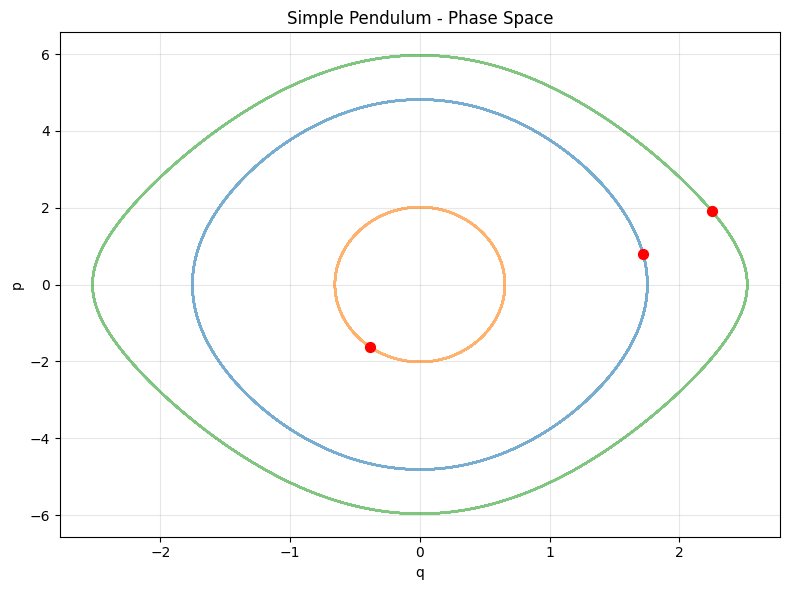

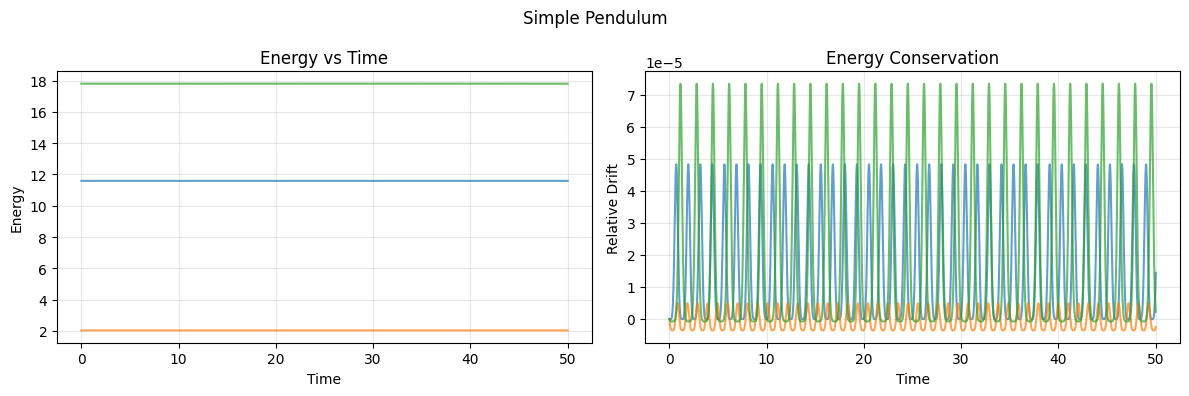

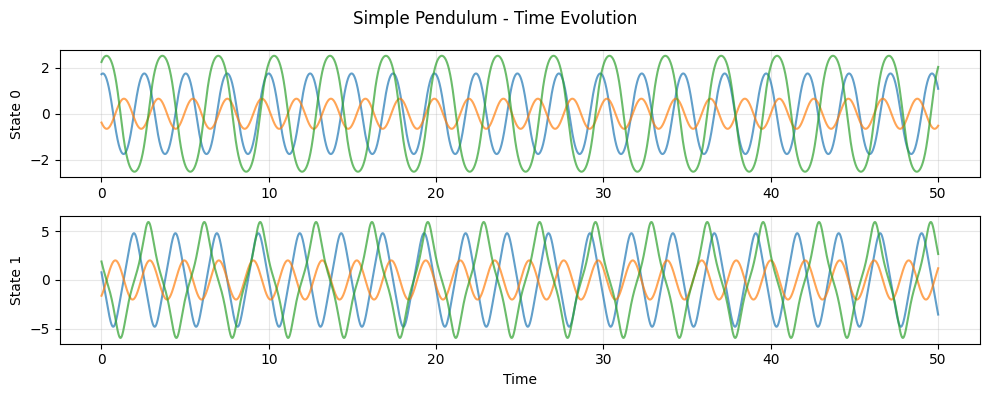

In [32]:
# Simple Pendulum
print("Simple Pendulum...")
pendulum = SimplePendulum(g=9.81, L=1.0, m=1.0)
plot_everything(pendulum, n_traj=3, tspan=(0, 50))
plt.show()



Mass-Spring System...


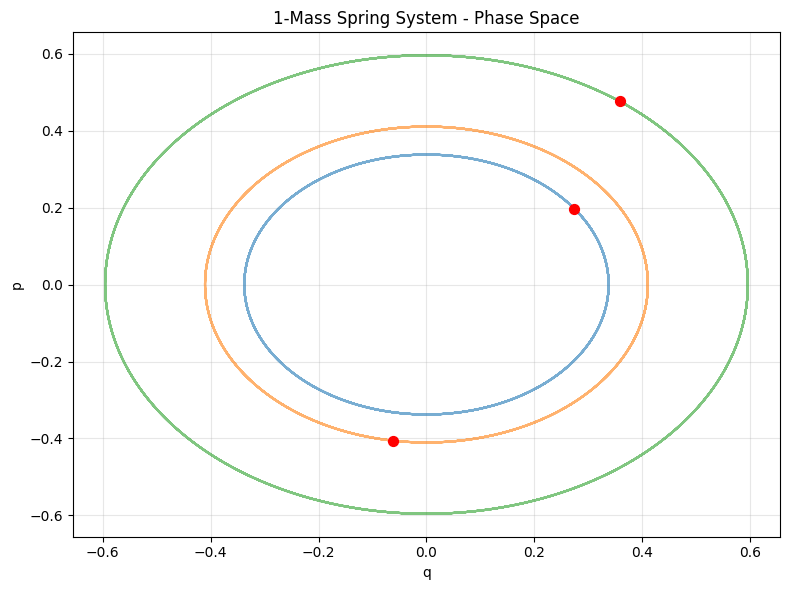

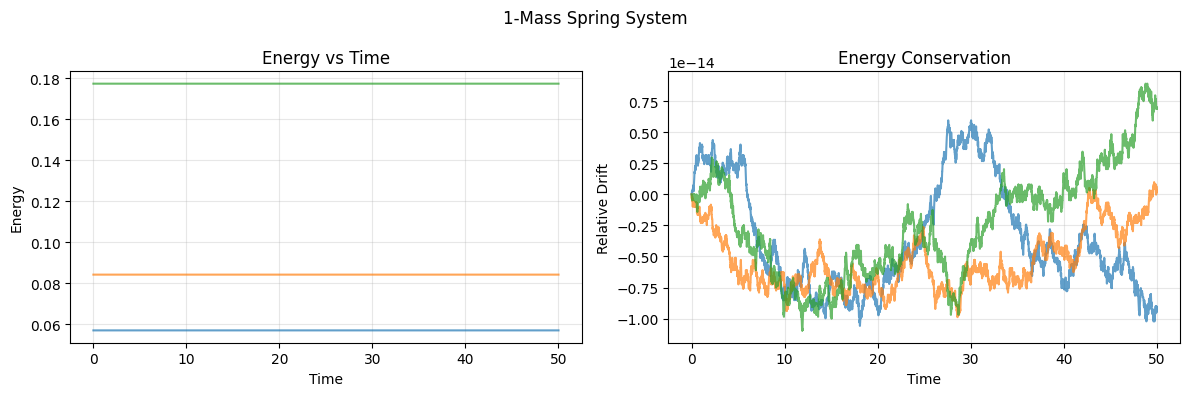

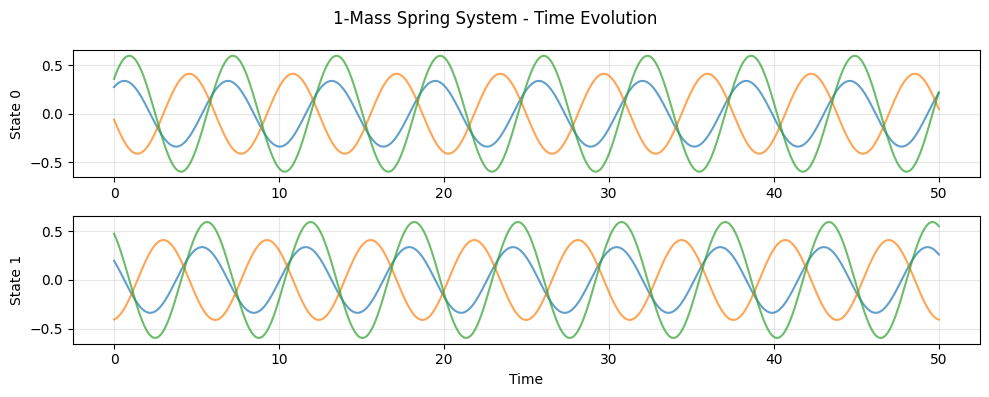

In [33]:
# Mass-Spring
print("Mass-Spring System...")
spring = MassSpringSystem(k=1.0, m=1.0)
plot_everything(spring, n_traj=3, tspan=(0, 50))
plt.show()

Double Pendulum...


/tmp/ipykernel_1309/2570586314.py:64: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  yh = fsolve ( midpoint_residual, yh, args = ( f, to, yo, th ), xtol=1e-12)


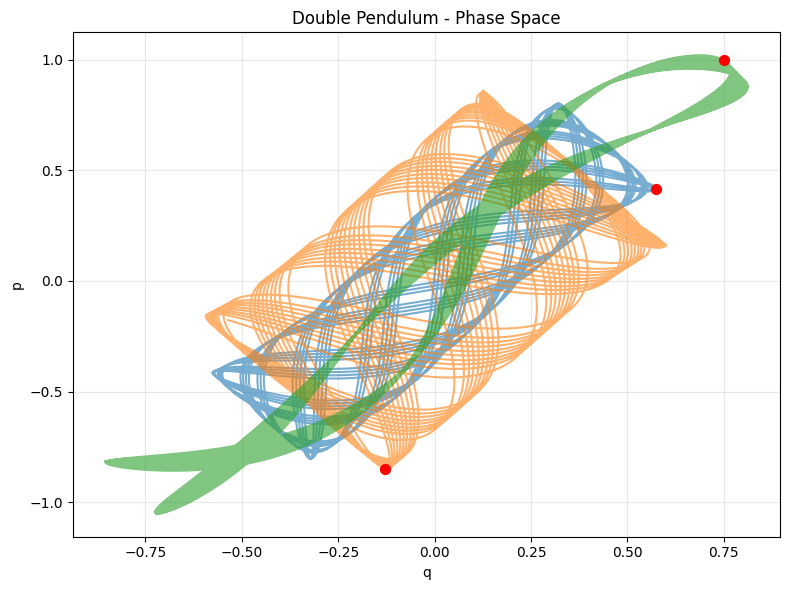

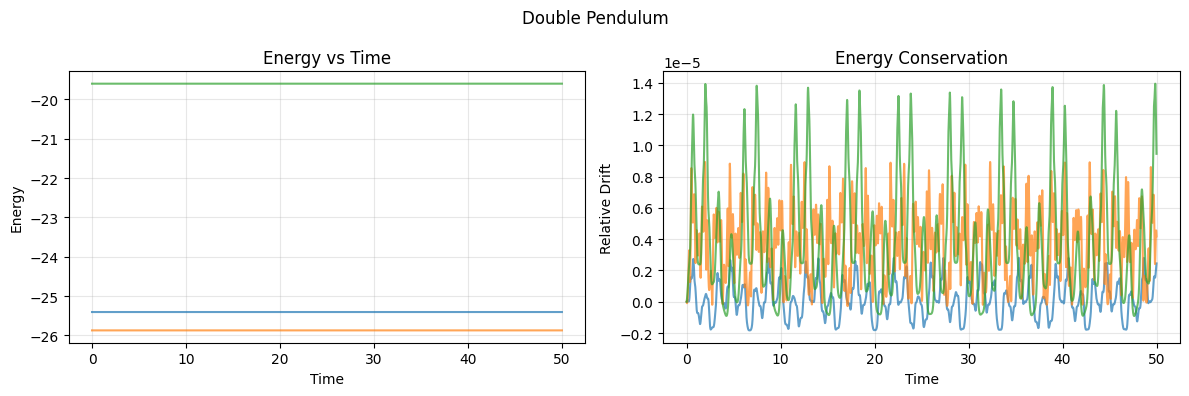

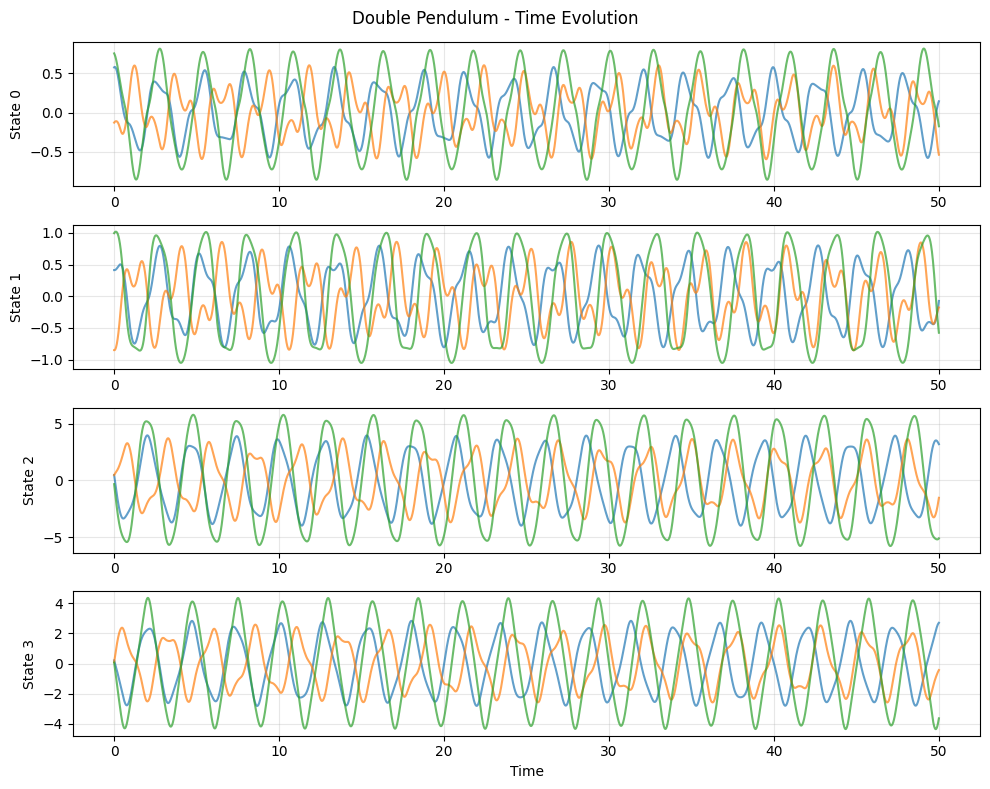

In [34]:
# Double Pendulum
print("Double Pendulum...")
double_pend = DoublePendulum(g=9.81, L1=1.0, L2=1.0, m1=1.0, m2=1.0)
plot_everything(double_pend, n_traj=3, tspan=(0, 50))
plt.show()

Coupled Oscillators...


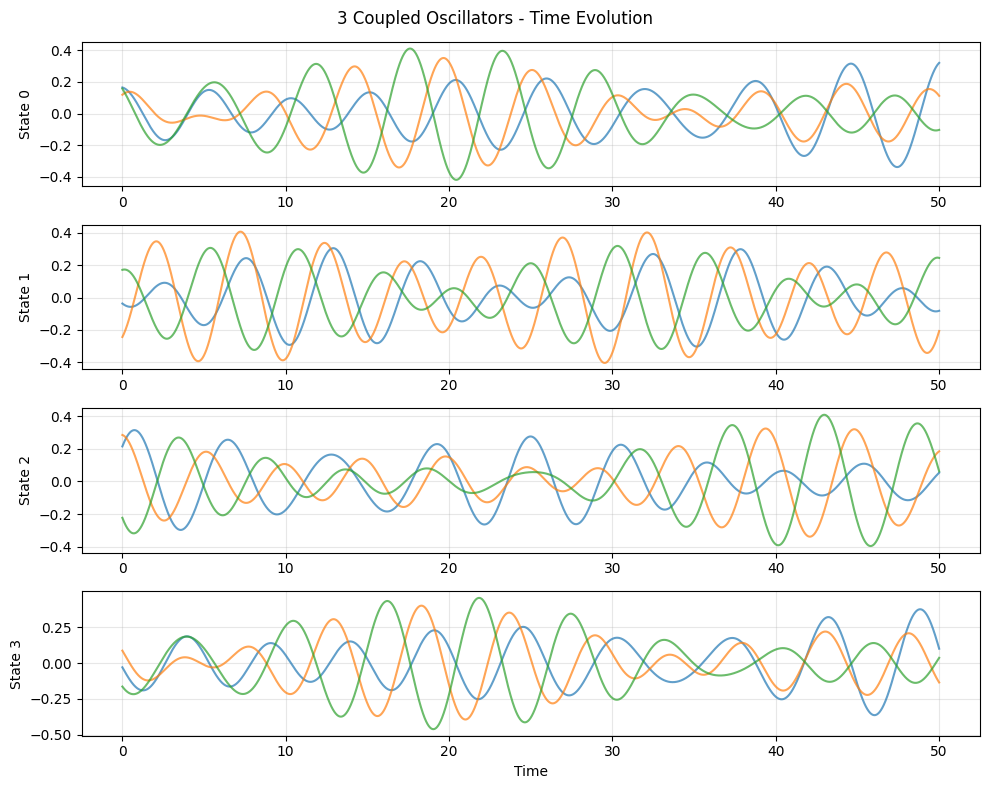

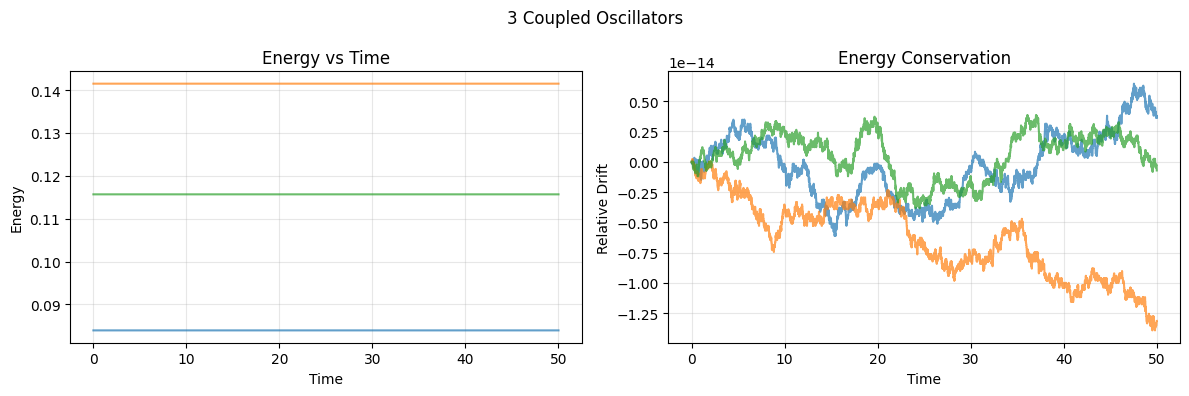

In [35]:
# Coupled Oscillators
print("Coupled Oscillators...")
coupled = CoupledOscillators(n=3, k=1.0, k_coupling=0.2, m=1.0)
plot_trajectories(coupled, n_traj=3, tspan=(0, 50))
plot_energy(coupled, n_traj=3, tspan=(0, 50))
plt.show()

In [36]:
def plot_3d_trajectories(system: NBodySystem, tspan: Tuple[float, float] = (0, 365),
                        steps: int = 5000):
    """Plot 3D orbital trajectories for N-body system"""
    t, traj, energy = simulate_system(system, system.initial_state, tspan, steps)

    # Extract positions for each body
    n = 3 * system.n_bodies
    positions = traj[:, :n].reshape(len(traj), system.n_bodies, 3)

    fig = plt.figure(figsize=(12, 10))
    ax = fig.add_subplot(111, projection='3d')

    # Plot trajectory for each body
    for i, body in enumerate(system.bodies):
        pos = positions[:, i, :]
        ax.plot(pos[:, 0], pos[:, 1], pos[:, 2],
               label=body.name, color=body.color, linewidth=1.5)
        # Mark initial position
        ax.scatter(pos[0, 0], pos[0, 1], pos[0, 2],
                  color=body.color, s=body.markersize*20, marker=body.marker)

    ax.set_xlabel('X (AU)')
    ax.set_ylabel('Y (AU)')
    ax.set_zlabel('Z (AU)')
    ax.set_title(f'{system.name} - 3D Trajectories')
    ax.legend()
    plt.tight_layout()


def plot_2d_orbits(system: NBodySystem, tspan: Tuple[float, float] = (0, 365),
                   steps: int = 5000):
    """Plot 2D (XY plane) orbital trajectories"""
    t, traj, energy = simulate_system(system, system.initial_state, tspan, steps)

    # Extract positions
    n = 3 * system.n_bodies
    positions = traj[:, :n].reshape(len(traj), system.n_bodies, 3)

    plt.figure(figsize=(10, 10))

    # Plot orbit for each body
    for i, body in enumerate(system.bodies):
        pos = positions[:, i, :]
        plt.plot(pos[:, 0], pos[:, 1],
                label=body.name, color=body.color, linewidth=2)
        plt.scatter(pos[0, 0], pos[0, 1],
                   color=body.color, s=body.markersize*20, marker=body.marker)

    plt.xlabel('X (AU)')
    plt.ylabel('Y (AU)')
    plt.title(f'{system.name} - Orbital Plane')
    plt.axis('equal')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()


def plot_nbody_energy(system: NBodySystem, tspan: Tuple[float, float] = (0, 365),
                     steps: int = 5000):
    """Plot energy conservation for N-body system"""
    t, traj, energy = simulate_system(system, system.initial_state, tspan, steps)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    # Absolute energy
    ax1.plot(t, energy, linewidth=2)
    ax1.set_xlabel('Time (days)')
    ax1.set_ylabel('Total Energy')
    ax1.set_title('Energy vs Time')
    ax1.grid(True, alpha=0.3)

    # Relative drift
    drift = (energy - energy[0]) / np.abs(energy[0])
    ax2.plot(t, drift, linewidth=2)
    ax2.set_xlabel('Time (days)')
    ax2.set_ylabel('Relative Energy Drift')
    ax2.set_title('Energy Conservation')
    ax2.grid(True, alpha=0.3)

    max_drift = np.max(np.abs(drift))
    ax2.text(0.05, 0.95, f'Max drift: {max_drift:.2e}',
            transform=ax2.transAxes, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

    plt.suptitle(f'{system.name}')
    plt.tight_layout()


def analyze_nbody(system: NBodySystem, tspan: Tuple[float, float] = (0, 365),
                 steps: int = 5000):
    """Complete N-body analysis: 3D + 2D + energy"""
    plot_3d_trajectories(system, tspan, steps)
    plot_2d_orbits(system, tspan, steps)
    plot_nbody_energy(system, tspan, steps)


1. Sun-Earth System
------------------------------------------------------------
Earth velocity: 0.017202 AU/day
Expected period: 365.3 days

Initial state check:
Positions (should have Z=0): [0. 0. 0. 1. 0. 0.]
Momenta (should have Z=0): [0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
 5.16052323e-08 0.00000000e+00]


/tmp/ipykernel_1309/2570586314.py:64: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  yh = fsolve ( midpoint_residual, yh, args = ( f, to, yo, th ), xtol=1e-12)


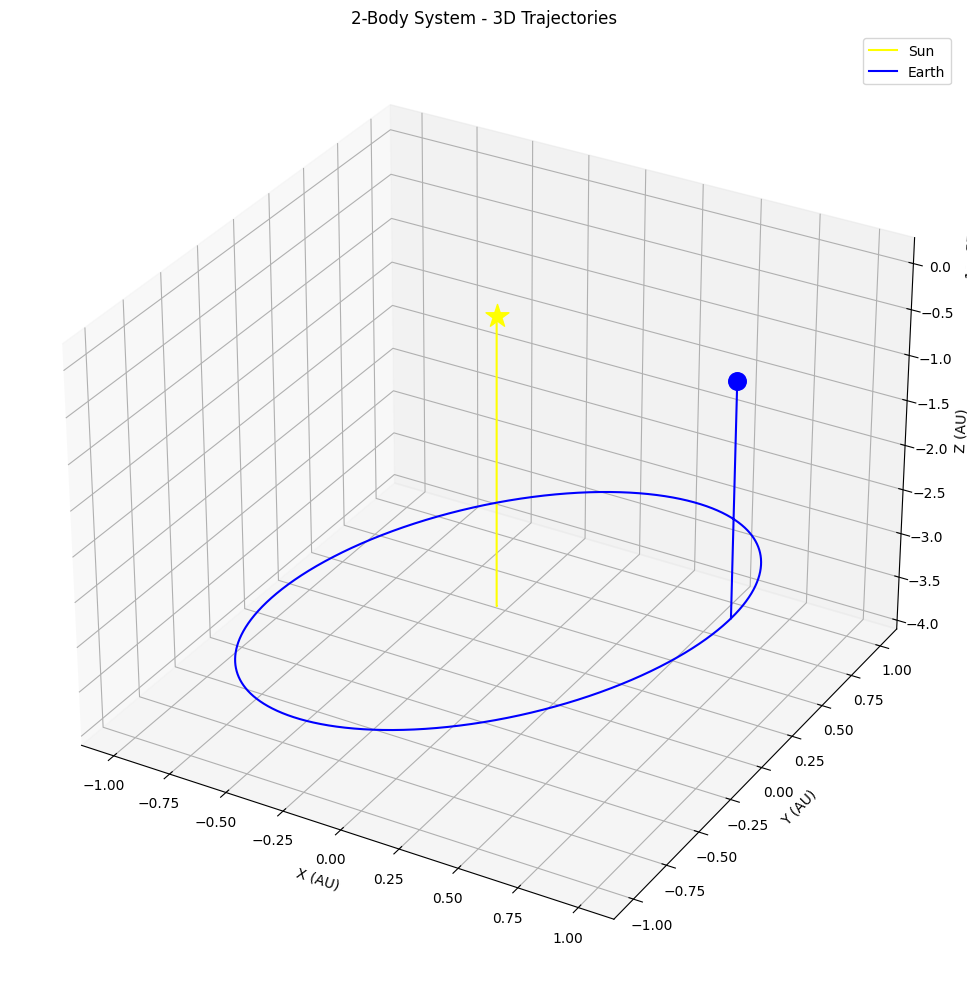

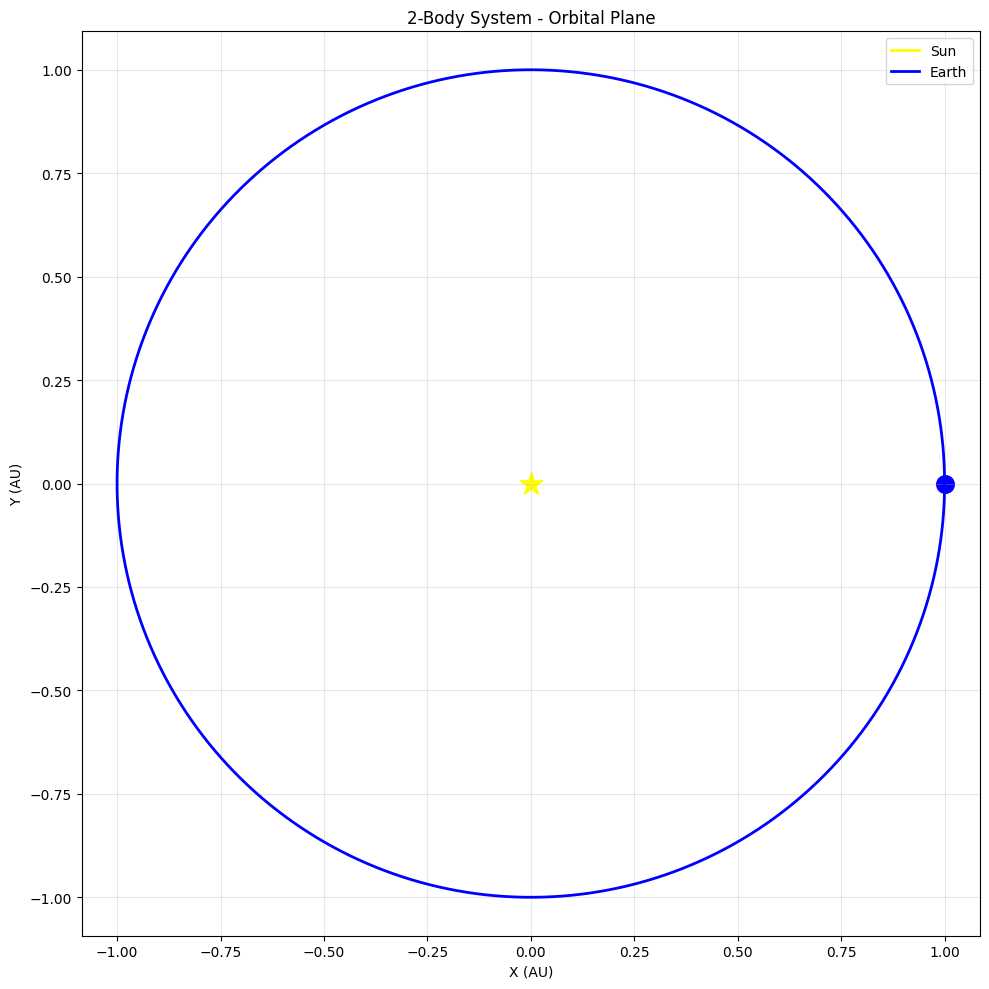

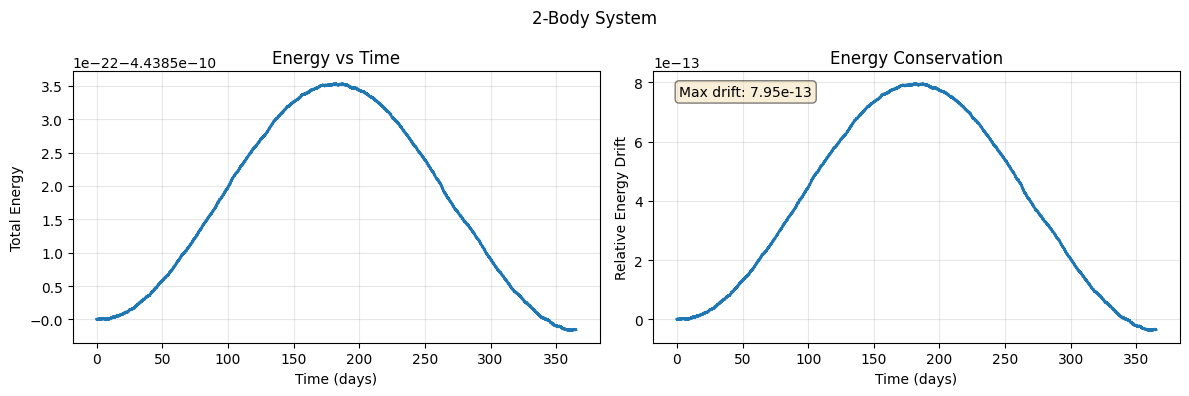

In [37]:
    # Example 1: Sun-Earth System (SIMPLE)
    print("1. Sun-Earth System")
    print("-" * 60)

    G = 2.959e-4  # AU³/(M_sun·day²)

    sun = CelestialBody(
        name="Sun",
        mass=1.0,
        initial_position=np.array([0.0, 0.0, 0.0]),
        initial_momentum=np.array([0.0, 0.0, 0.0]),
        color='yellow',
        marker='*',
        markersize=15
    )

    # Earth: circular orbit at 1 AU
    earth_mass = 3.0e-6
    earth_radius = 1.0
    earth_velocity = np.sqrt(G * 1.0 / earth_radius)  # Circular orbit velocity

    print(f"Earth velocity: {earth_velocity:.6f} AU/day")
    print(f"Expected period: {2*np.pi*earth_radius/earth_velocity:.1f} days")

    earth = CelestialBody(
        name="Earth",
        mass=earth_mass,
        initial_position=np.array([earth_radius, 0.0, 0.0]),
        initial_momentum=np.array([0.0, earth_mass * earth_velocity, 0.0]),
        color='blue',
        marker='o',
        markersize=8
    )

    sun_earth = NBodySystem([sun, earth], use_barycenter_frame=False)

    # Check initial state
    print(f"\nInitial state check:")
    print(f"Positions (should have Z=0): {sun_earth.initial_state[:6]}")
    print(f"Momenta (should have Z=0): {sun_earth.initial_state[6:]}")

    analyze_nbody(sun_earth, tspan=(0, 365), steps=15000)


Simulating Sun-Earth-Jupiter System...


/tmp/ipykernel_1309/2570586314.py:64: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  yh = fsolve ( midpoint_residual, yh, args = ( f, to, yo, th ), xtol=1e-12)


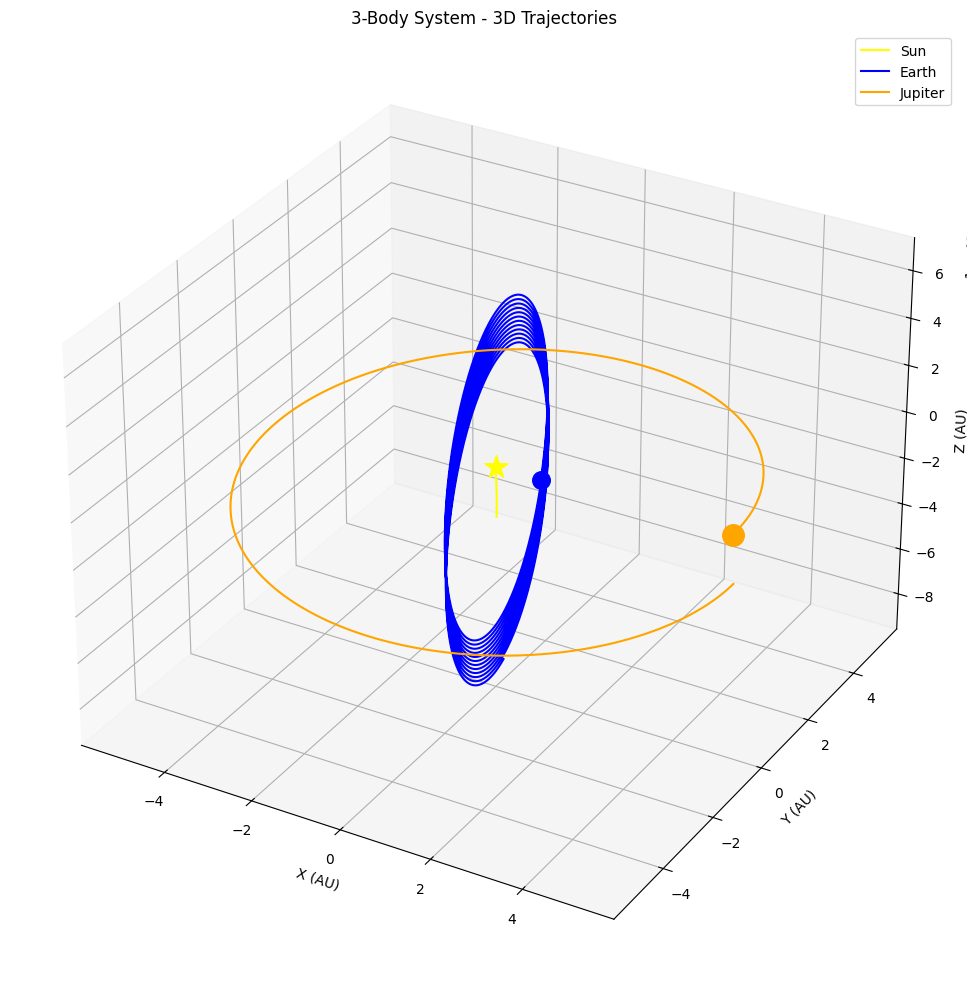

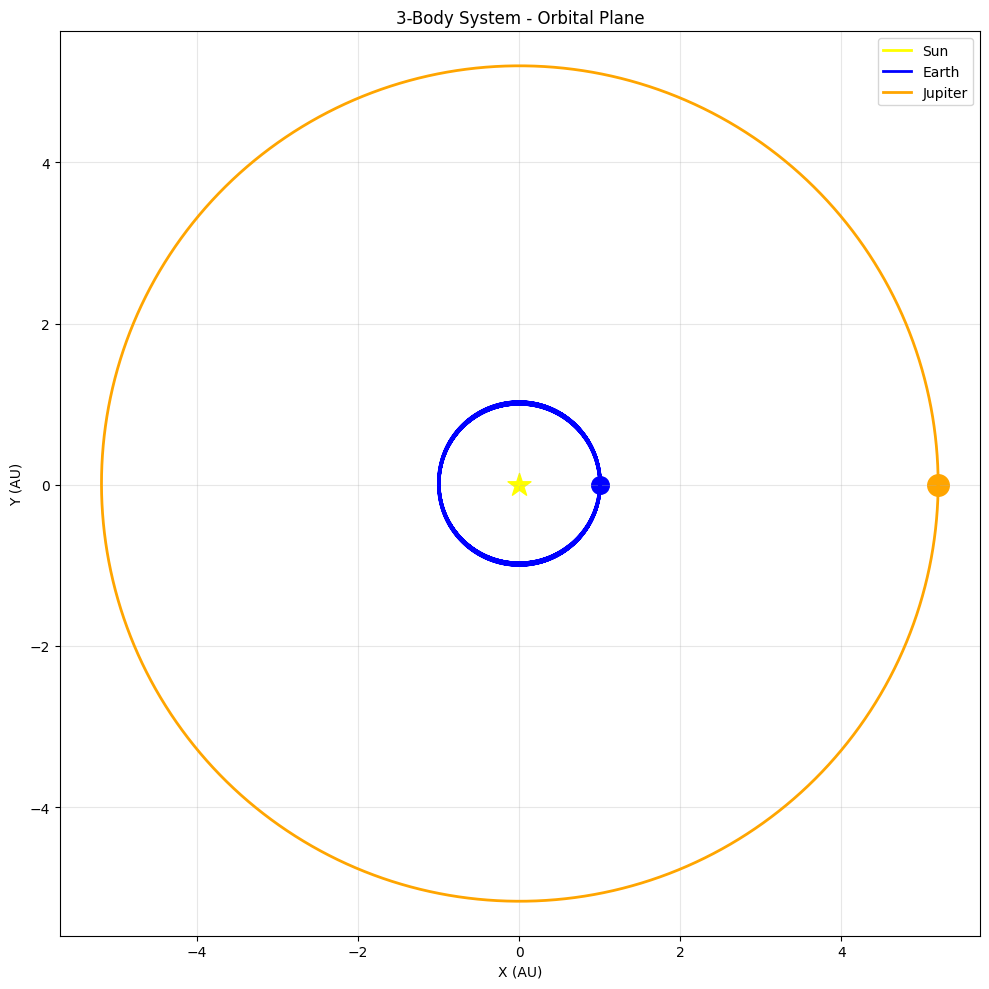

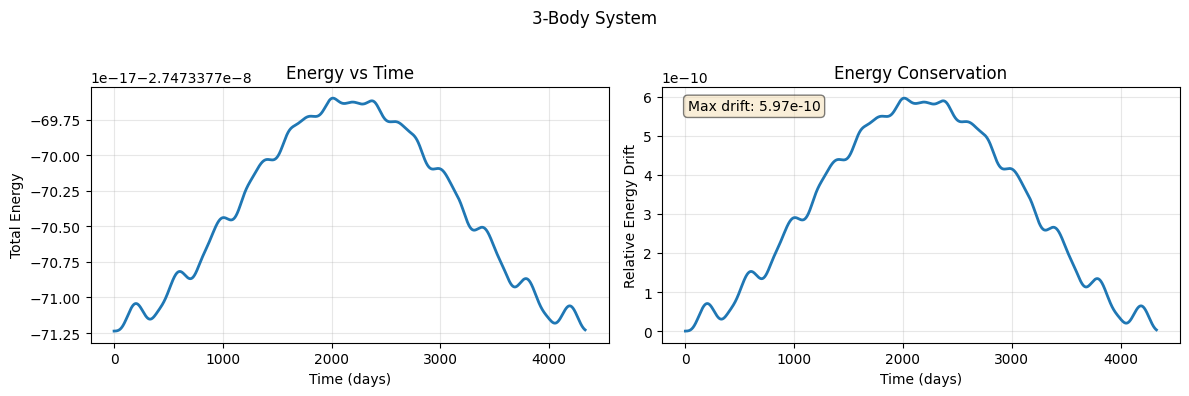

In [38]:
    # Example 2: Sun-Earth-Jupiter System
    print("Simulating Sun-Earth-Jupiter System...")

    jupiter_velocity = np.sqrt(2.959e-4 * 1.0 / 5.2)
    jupiter_mass = 9.5e-4

    jupiter = CelestialBody(
        name="Jupiter",
        mass=jupiter_mass,
        initial_position=np.array([5.2, 0.0, 0.0]),
        initial_momentum=np.array([0.0, jupiter_mass * jupiter_velocity, 0.0]),  # Y direction only
        color='orange',
        marker='o',
        markersize=12
    )

    solar_system = NBodySystem([sun, earth, jupiter], use_barycenter_frame=False)
    analyze_nbody(solar_system, tspan=(0, 4330), steps=10000)


2. Binary Star System
   Orbital velocity: 0.008601 AU/day
   Orbital period: 730.5 days


/tmp/ipykernel_1309/2570586314.py:64: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  yh = fsolve ( midpoint_residual, yh, args = ( f, to, yo, th ), xtol=1e-12)


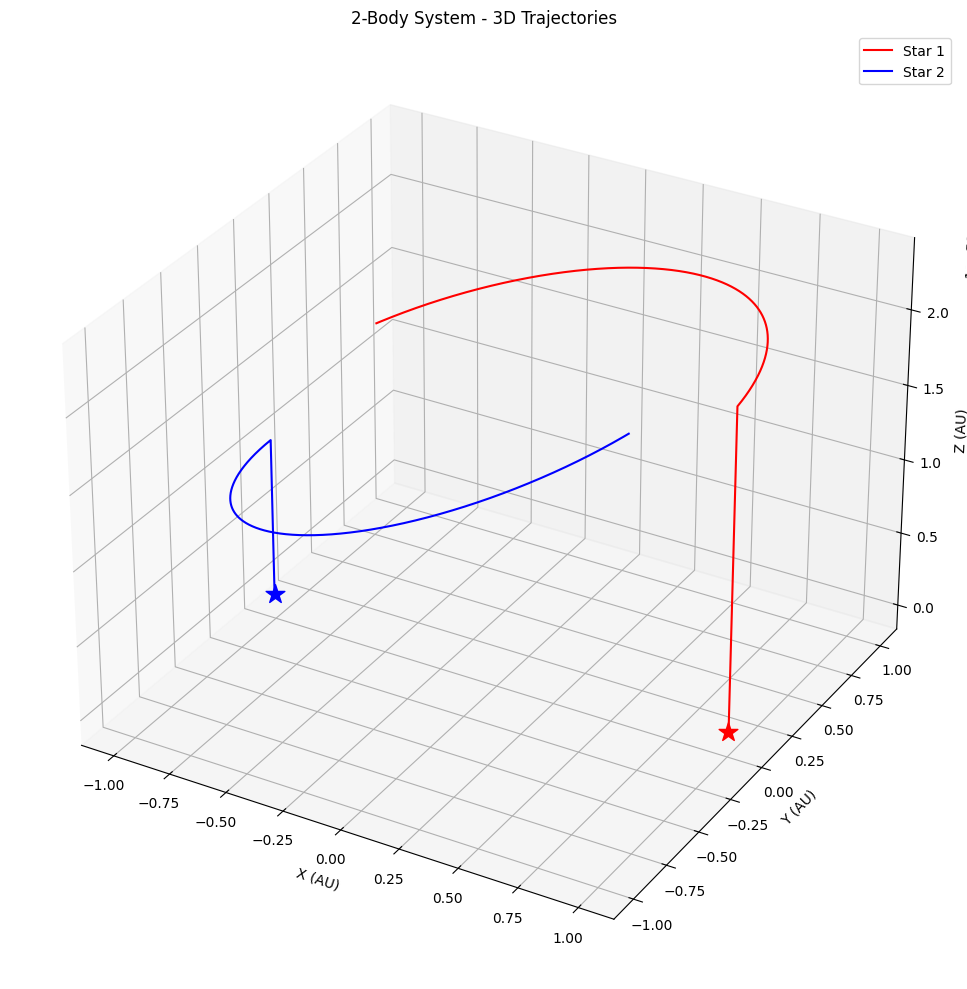

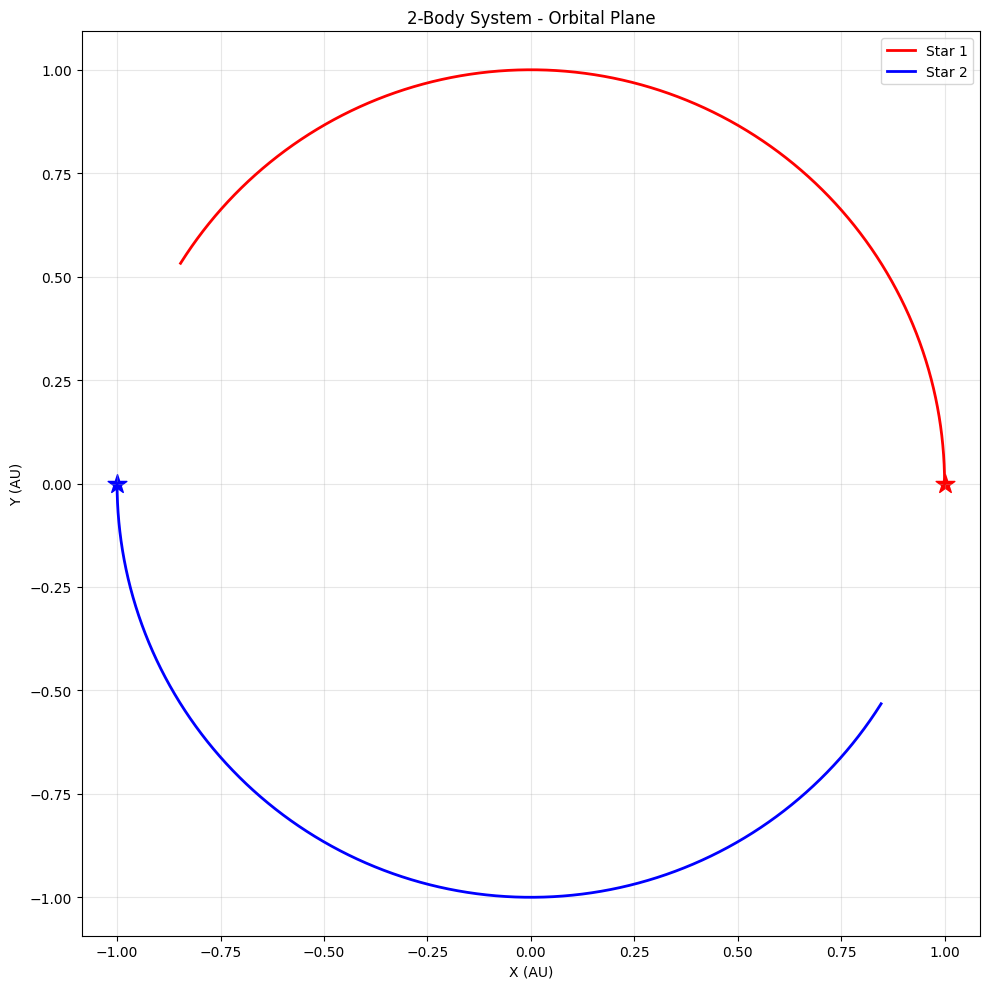

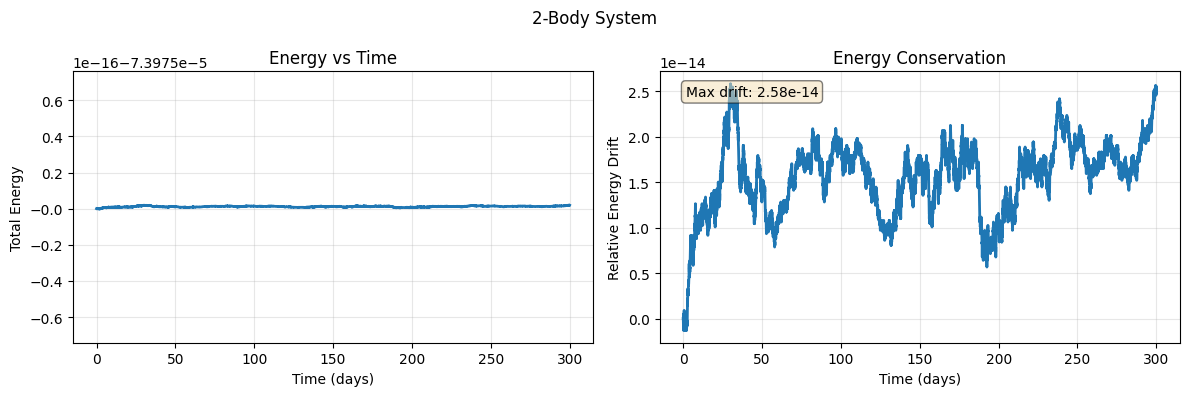

In [39]:
    # Example 2: Binary Star System
    print("\n2. Binary Star System")
    G = 2.959e-4
    star_mass = 1.0
    separation = 2.0
    radius = 1.0
    orbital_velocity = np.sqrt(G * star_mass * radius / (separation**2))

    print(f"   Orbital velocity: {orbital_velocity:.6f} AU/day")
    print(f"   Orbital period: {2*np.pi*radius/orbital_velocity:.1f} days")

    star1 = CelestialBody(
        name="Star 1", mass=star_mass,
        initial_position=np.array([radius, 0.0, 0.0]),
        initial_momentum=np.array([0.0, star_mass * orbital_velocity, 0.0]),
        color='red', marker='*', markersize=10
    )

    star2 = CelestialBody(
        name="Star 2", mass=star_mass,
        initial_position=np.array([-radius, 0.0, 0.0]),
        initial_momentum=np.array([0.0, -star_mass * orbital_velocity, 0.0]),
        color='blue', marker='*', markersize=10
    )

    binary = NBodySystem([star1, star2], use_barycenter_frame=False)
    analyze_nbody(binary, tspan=(0, 300), steps=15000)

Simulating Three-Body Lagrange Triangle...


/tmp/ipykernel_1309/2570586314.py:64: RuntimeWarning: The iteration is not making good progress, as measured by the 
 improvement from the last ten iterations.
  yh = fsolve ( midpoint_residual, yh, args = ( f, to, yo, th ), xtol=1e-12)


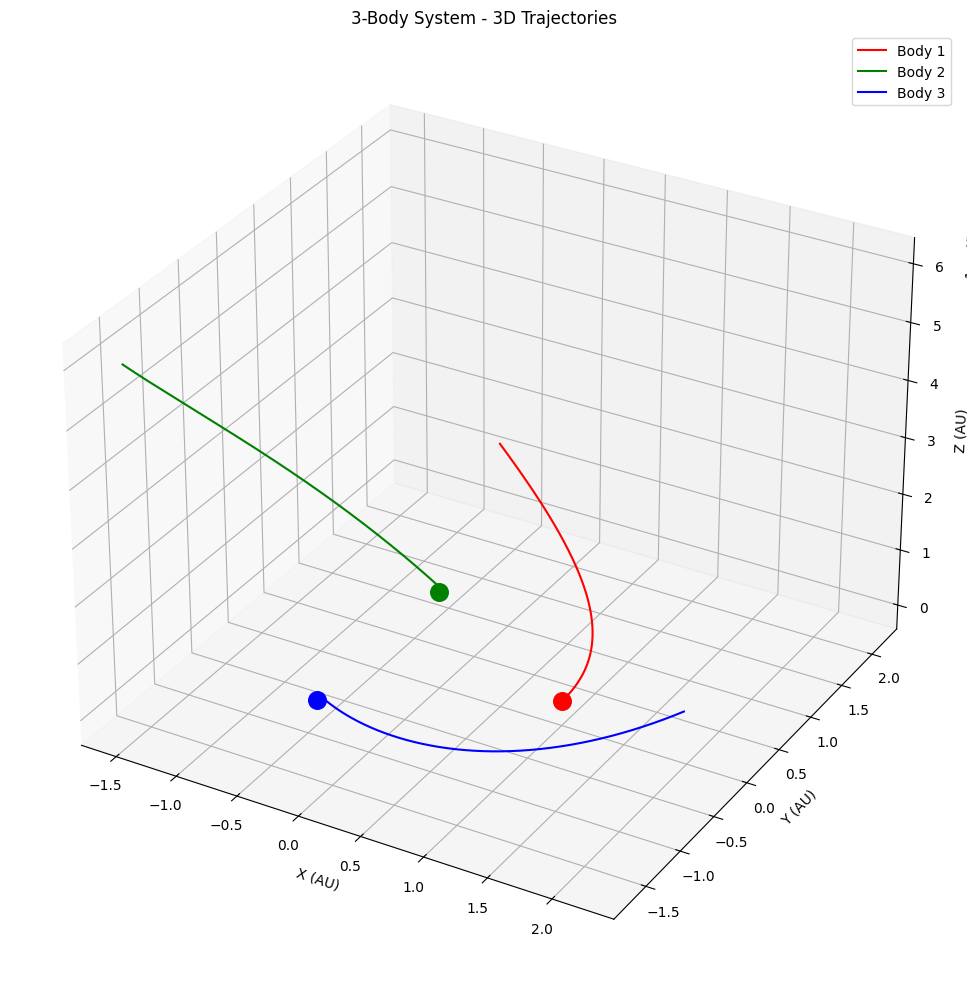

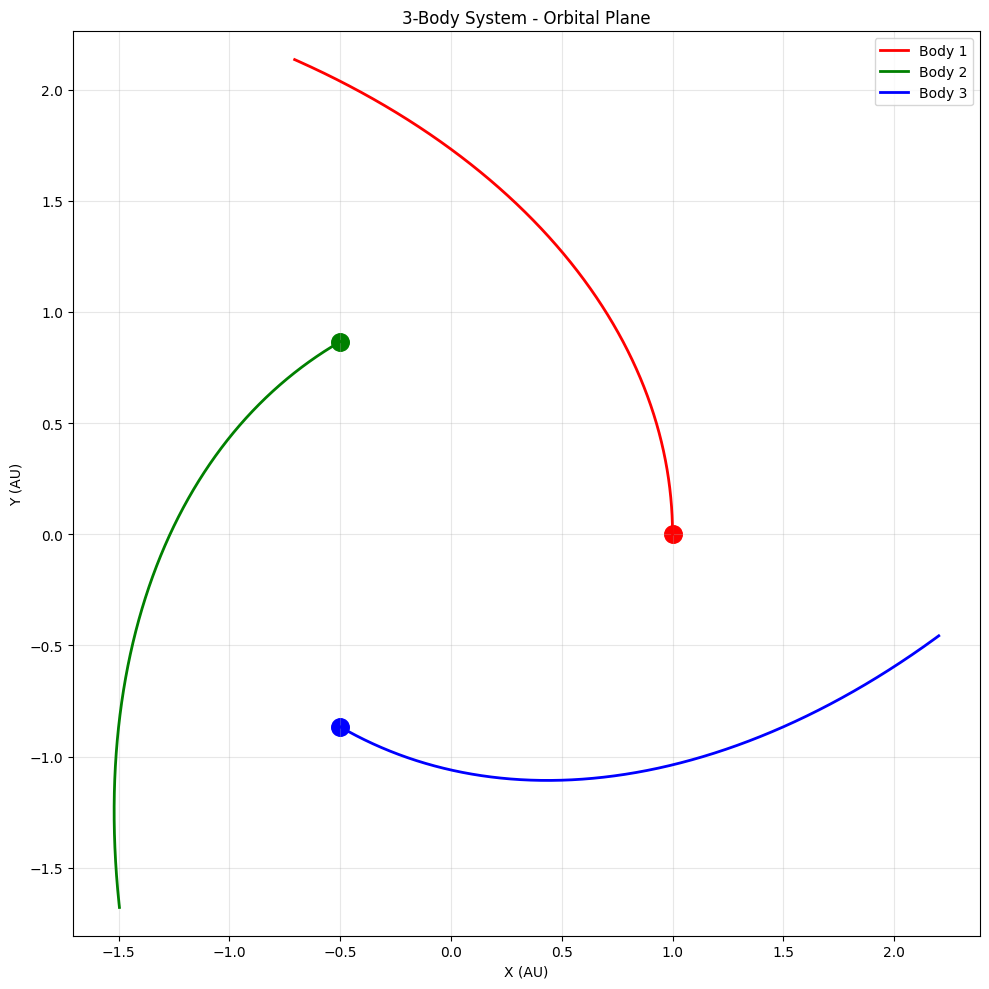

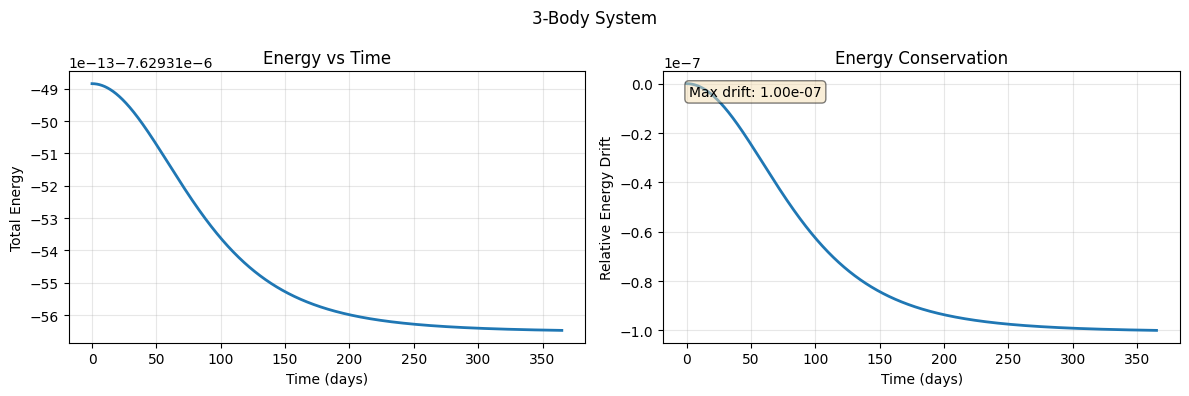

In [40]:

    # Example 4: Three-Body System (Lagrange Configuration)
    print("Simulating Three-Body Lagrange Triangle...")

    # Equilateral triangle configuration - stable!
    body_mass = 1.0 / 3.0  # Equal masses
    radius = 1.0  # Distance from center
    angle_sep = 2 * np.pi / 3  # 120 degrees

    # Circular orbit velocity for this configuration
    v_orbit = np.sqrt(2.959e-4 * 1.0 / radius) / np.sqrt(3)

    positions = []
    momenta = []
    for i in range(3):
        angle = i * angle_sep
        pos = np.array([radius * np.cos(angle), radius * np.sin(angle), 0.0])
        # Velocity perpendicular to radius
        vel = v_orbit * np.array([-np.sin(angle), np.cos(angle), 0.0])
        positions.append(pos)
        momenta.append(body_mass * vel)

    body1_lag = CelestialBody(
        name="Body 1", mass=body_mass,
        initial_position=positions[0], initial_momentum=momenta[0],
        color='red', marker='o', markersize=8
    )
    body2_lag = CelestialBody(
        name="Body 2", mass=body_mass,
        initial_position=positions[1], initial_momentum=momenta[1],
        color='green', marker='o', markersize=8
    )
    body3_lag = CelestialBody(
        name="Body 3", mass=body_mass,
        initial_position=positions[2], initial_momentum=momenta[2],
        color='blue', marker='o', markersize=8
    )

    lagrange = NBodySystem([body1_lag, body2_lag, body3_lag], use_barycenter_frame=False)
    analyze_nbody(lagrange, tspan=(0, 365), steps=8000)


    plt.show()